# L1 — Exploration du jeu de données « network slicing » (Farreras et al., 2024)

**Objectif.** Comprendre ce que contient réellement le jeu de données avant de formuler le problème d'apprentissage :
combien de scénarios et de topologies, quelles variables, quelle qualité, et comment la cible (délai par flux)
dépend des entrées.

**Rappel du vocabulaire.**
- *Scénario* = une simulation complète : une topologie, des slices admises, du trafic, un routage → des mesures.
- *Flux* = un trafic d'un nœud source (un équipement d'une slice) vers une destination ; c'est l'unité de prédiction.
- *Lien* = un lien orienté du graphe, avec une capacité en bits/s.
- *ρ (rho)* = charge offerte / capacité. Si ρ ≥ 1, le lien reçoit plus qu'il ne peut transmettre.

Le parsing brut (`src/parsing.py`, validé contre l'API officielle par `tests/test_parsing.py`) a produit 4 tables :
`scenarios`, `links`, `flows`, `flow_links` (un saut d'un flux sur un lien). `src/features.py` calcule ensuite,
**uniquement à partir des entrées**, les charges, utilisations et estimations de files d'attente.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import RESULTS_DIR, PROCESSED_DIR, SLICE_TYPES
from src.features import build_all, load_tables, ALL_FEATURES, FEATURE_GROUPS
from src.eda import (quality_report, impossible_values, fig_inventory, fig_targets, fig_delay_vs,
                     fig_rho_validation, fig_correlations, fig_corr_matrix)
from src.plotting import set_style, savefig
from src.variables import save_variables_table

set_style()
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
summary = {}   # every number quoted in the report is written to results/eda_summary.json

ModuleNotFoundError: No module named 'src'

## 1. Inventaire de l'archive

In [ ]:
raw = load_tables()
out = build_all()                       # features calculées depuis les entrées (cache parquet)
scen, f, links, hops = out["scenarios"], out["flows"], out["links"], out["hops"]

n_tars = scen.tar_file.nunique()
inv = {
    "n_tarballs": int(n_tars),
    "n_scenarios_ok": int(len(scen)),
    "n_scenarios_skipped_not_ok": int(scen.groupby("tar_file").n_skipped_in_tar.first().sum()),
    "n_topologies": int(scen.topology.nunique()),
    "n_flows": int(len(f)),
    "n_hops": int(len(hops)),
    "n_links_used": int(len(links)),
    "flows_per_slice_type": f.slice_type.value_counts().to_dict(),
}
summary["inventory"] = inv
print(json.dumps(inv, indent=1))

{
 "n_tarballs": 4,
 "n_scenarios_ok": 360,
 "n_scenarios_skipped_not_ok": 40,
 "n_topologies": 127,
 "n_flows": 73503,
 "n_hops": 354421,
 "n_links_used": 78961,
 "flows_per_slice_type": {
  "mMTC": 53981,
  "URLLC": 16221,
  "eMBB": 3301
 }
}


In [ ]:
desc = scen[["n_nodes", "n_core_nodes", "n_core_links", "n_links", "n_flows", "n_slices",
             "n_slices_eMBB", "n_slices_URLLC", "n_slices_mMTC", "sim_wallclock_s"]].describe().T
summary["scenario_describe"] = desc[["mean", "min", "50%", "max"]].round(2).to_dict(orient="index")
desc

,count,mean,std,min,25%,50%,75%,max
n_nodes,360.0,229.066667,169.445322,25.0,98.00,169.5,313.5,704.0
n_core_nodes,360.0,18.891667,15.606296,2.0,8.00,16.0,25.0,124.0
n_core_links,360.0,36.166667,33.535497,0.0,14.00,32.0,48.0,252.0
n_links,360.0,464.150000,338.929545,48.0,203.50,346.0,628.5,1416.0
n_flows,360.0,204.175000,168.705360,4.0,75.00,143.5,288.5,683.0
n_slices,360.0,22.794444,14.113625,4.0,13.00,20.0,30.0,94.0
n_slices_eMBB,360.0,4.816667,3.146338,1.0,2.00,4.0,7.0,16.0
n_slices_URLLC,360.0,8.430556,7.025672,0.0,4.00,7.0,11.0,47.0
n_slices_mMTC,360.0,9.547222,7.788857,0.0,4.00,7.0,13.0,54.0
sim_wallclock_s,360.0,38221.466667,28295.377773,666.0,17705.25,32561.0,51660.0,167101.0


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


{'n': 127, 'scen_per_topo_min': 1, 'scen_per_topo_median': 3.0, 'scen_per_topo_max': 9, 'core_nodes_min': 2, 'core_nodes_max': 124}


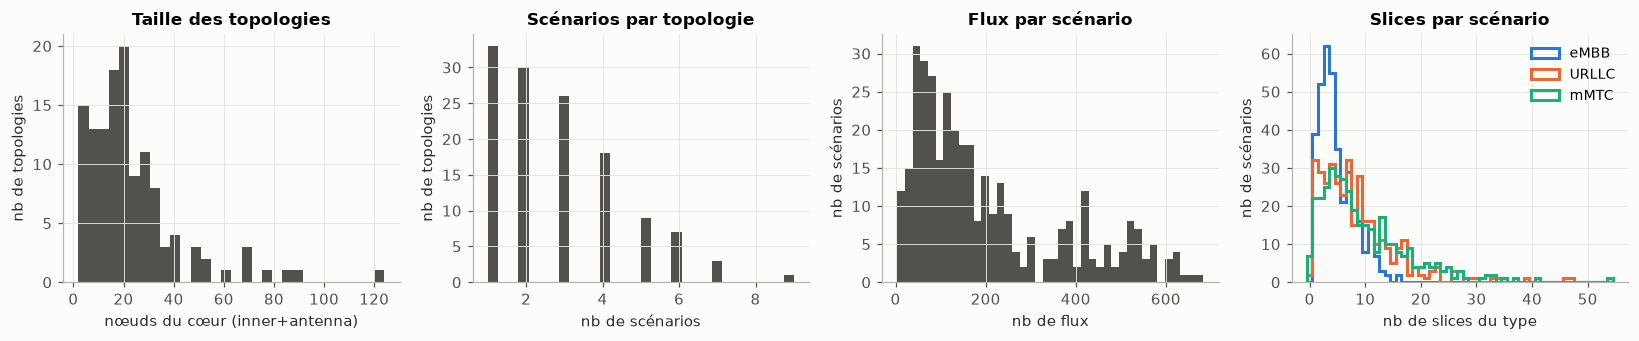

In [ ]:
topo = scen.groupby("topology").agg(n_scen=("scenario_id", "size"), n_core_nodes=("n_core_nodes", "first"),
                                    n_core_links=("n_core_links", "first"))
summary["topologies"] = {"n": int(len(topo)), "scen_per_topo_min": int(topo.n_scen.min()),
                         "scen_per_topo_median": float(topo.n_scen.median()), "scen_per_topo_max": int(topo.n_scen.max()),
                         "core_nodes_min": int(topo.n_core_nodes.min()), "core_nodes_max": int(topo.n_core_nodes.max())}
print(summary["topologies"])
fig = fig_inventory(scen); savefig(fig, "L1_01_inventaire"); plt.show()

**Structure d'un scénario.** Chaque graphe contient : un *cœur* issu de Topology Zoo (nœuds `inner`),
des nœuds `antenna` (points d'accès radio), un nœud feuille `origin_*` par source de trafic accroché à une antenne,
et des nœuds `destination_*` par type de slice. Le grand nombre de nœuds (`n_nodes`) vient donc surtout des
sources mMTC (une par capteur), pas de la taille du cœur.

In [ ]:
types = raw["links"].groupby(["src_type", "dst_type"]).size().sort_values(ascending=False).head(12)
types

src_type           dst_type         
antenna            origin_mmtc          53981
origin_mmtc        antenna              53981
antenna            origin_urllc         16221
origin_urllc       antenna              16221
inner              inner                 8796
origin_embb        antenna               3301
antenna            origin_embb           3301
                   inner                 1756
inner              antenna               1756
destination_mmtc   destination_mmtc       720
destination_urllc  destination_urllc      720
destination_embb   destination_embb       720
dtype: int64

## 2. Qualité des données : types, manquants, doublons, valeurs impossibles

In [ ]:
qr = quality_report(raw)
qr.to_csv(RESULTS_DIR / "quality_report.csv", index=False)
print("Colonnes avec valeurs manquantes :")
print(qr[qr.n_missing > 0][["table", "column", "n_missing", "n_rows"]].to_string(index=False))
print("\nClés dupliquées par table :", qr.groupby("table").n_duplicate_keys_in_table.first().to_dict())

Colonnes avec valeurs manquantes :
table            column  n_missing  n_rows
links meas_avg_pkt_size      88133  167094

Clés dupliquées par table : {'flow_links': 0, 'flows': 0, 'links': 0, 'scenarios': 0}


Les seules valeurs manquantes attendues sont `meas_*` (statistiques mesurées) sur les liens que le simulateur
ne rapporte pas, et `exp_max_factor` si un flux n'est pas poissonien. Ce sont des sorties ou des constantes, pas des entrées.

In [ ]:
iv = impossible_values(f)
summary["impossible_values"] = iv
iv

{'delay_sentinel_-1 (no packet delivered)': 1,
 'delay_negative_other': 0,
 'jitter_negative_other': 0,
 'loss_gt_1': 0,
 'loss_negative': 0,
 'pkts_gen_zero': 0,
 'rate_bps_nonpositive': 0,
 'nan_in_targets': 0,
 'percentiles_not_sorted': 0}

In [ ]:
const = {c: f[c].unique().tolist()[:5] for c in ["time_dist", "size_dist", "exp_max_factor"]}
const["max_avg_lambda"] = scen.max_avg_lambda.unique().tolist()[:5]
const["sched_policy"] = raw["links"].sched_policy.unique().tolist()
const["queue_size_pkts"] = sorted(hops.queue_size_pkts.unique().tolist())[:10]
const["rate_bps_by_slice"] = f.groupby("slice_type").rate_bps.unique().apply(lambda v: sorted(v.tolist())[:5]).to_dict()
summary["constants"] = {k: [str(x) for x in v] if isinstance(v, list) else {kk: [str(x) for x in vv] for kk, vv in v.items()} for k, v in const.items()}
const

{'time_dist': [0],
 'size_dist': [2],
 'exp_max_factor': [10.0],
 'max_avg_lambda': [18000000.0],
 'sched_policy': ['WFQ', 'FIFO'],
 'queue_size_pkts': [32],
 'rate_bps_by_slice': {'URLLC': [3498560.0],
  'eMBB': [22500000.0],
  'mMTC': [250000.0]}}

**Vérification du débit réel (JOURNAL D0.3).** Le débit offert est calculé depuis les paramètres du générateur
(`AvgPktsLambda × taille moyenne`). On le compare au débit généré mesuré par le simulateur.

In [ ]:
ratio = f.avg_bw_kbps * 1000 / f.rate_bps
nominal_ratio = (f.rate_bps / f.nominal_bw).groupby(f.slice_type).median()
summary["rate_check"] = {"measured_over_rate_median": float(ratio.median()),
                         "measured_over_rate_p01": float(ratio.quantile(0.01)),
                         "measured_over_rate_p99": float(ratio.quantile(0.99)),
                         "rate_over_nominal_by_slice": nominal_ratio.round(4).to_dict()}
summary["rate_check"]

{'measured_over_rate_median': 1.000045733101619,
 'measured_over_rate_p01': 0.998908,
 'measured_over_rate_p99': 1.001208,
 'rate_over_nominal_by_slice': {'URLLC': 0.9996, 'eMBB': 1.25, 'mMTC': 1.25}}

**Le routage simulé diffère souvent du chemin déclaré dans `slices_K.json` (JOURNAL D1.1).**
Le parseur utilise `routing_K.txt`. Preuve : l'utilisation calculée avec ces chemins reproduit l'utilisation
mesurée par le simulateur.

In [ ]:
Lm = links[links.meas_util.notna()]
summary["routing_check"] = {
    "frac_flows_path_equal_slice_file": float(f.path_matches_slice_file.mean()),
    "frac_scenarios_all_paths_equal": float(f.groupby("scenario_id").path_matches_slice_file.all().mean()),
    "corr_min_rho1_vs_meas_util": float(np.corrcoef(np.minimum(Lm.rho_link, 1), Lm.meas_util)[0, 1]),
    "mae_min_rho1_vs_meas_util": float(np.abs(np.minimum(Lm.rho_link, 1) - Lm.meas_util).mean()),
    "frac_used_links_rho_gt_1": float((links.rho_link > 1).mean()),
}
summary["routing_check"]

{'frac_flows_path_equal_slice_file': 0.5655415425220739,
 'frac_scenarios_all_paths_equal': 0.21944444444444444,
 'corr_min_rho1_vs_meas_util': 0.984224572483901,
 'mae_min_rho1_vs_meas_util': 0.003600232524587686,
 'frac_used_links_rho_gt_1': 0.022112181963247678}

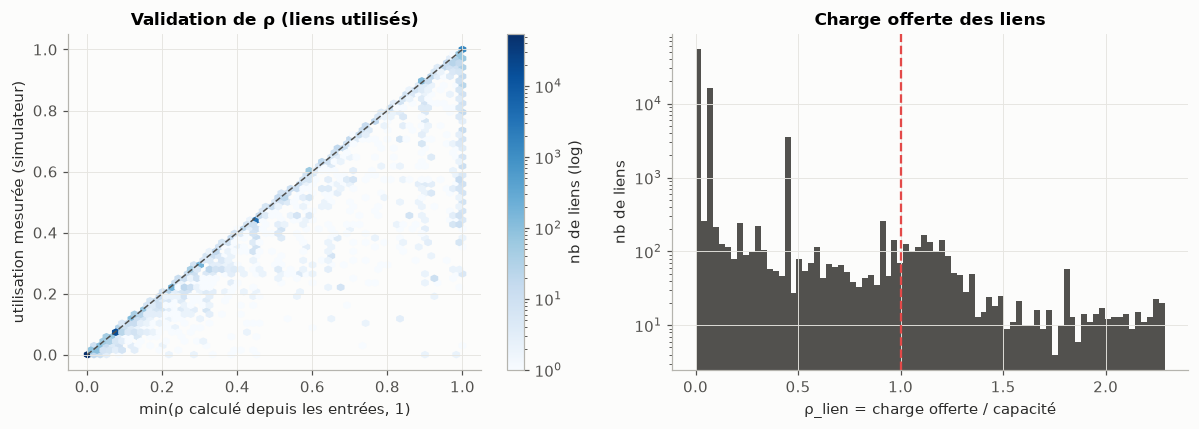

In [ ]:
fig = fig_rho_validation(links); savefig(fig, "L1_02_validation_rho"); plt.show()

## 3. Distribution des cibles

In [ ]:
d = f[f.has_delay]
tq = d.groupby("slice_type").delay.describe(percentiles=[0.01, 0.1, 0.5, 0.9, 0.99]).round(6)
summary["delay_by_slice"] = tq.to_dict(orient="index")
summary["delay_global"] = {"min": float(d.delay.min()), "median": float(d.delay.median()), "max": float(d.delay.max()),
                           "max_over_min_orders_of_magnitude": float(np.log10(d.delay.max() / d.delay.min())),
                           "skew_raw": float(d.delay.skew()), "skew_log10": float(np.log10(d.delay).skew()),
                           "frac_delay_gt_1s": float((d.delay > 1).mean())}
summary["loss_by_slice"] = f.groupby("slice_type").loss.describe(percentiles=[0.5, 0.9]).round(4).to_dict(orient="index")
print(json.dumps(summary["delay_global"], indent=1))
tq

{
 "min": 1.1e-05,
 "median": 0.001403,
 "max": 962.89,
 "max_over_min_orders_of_magnitude": 7.9421839912480845,
 "skew_raw": 29.002641930928746,
 "skew_log10": 1.047888804073574,
 "frac_delay_gt_1s": 0.031169219885173193
}


,count,mean,std,min,1%,10%,50%,90%,99%,max
slice_type,,,,,,,,,,
URLLC,16221.0,0.983699,6.767238,0.000025,0.000035,0.000068,0.000641,0.006533,30.57068,125.4040
eMBB,3300.0,15.029978,78.974858,0.000518,0.000591,0.001031,0.012490,0.070373,473.33598,962.8900
mMTC,53981.0,0.395312,3.243156,0.000011,0.000013,0.000034,0.001672,0.027503,12.78880,51.4377


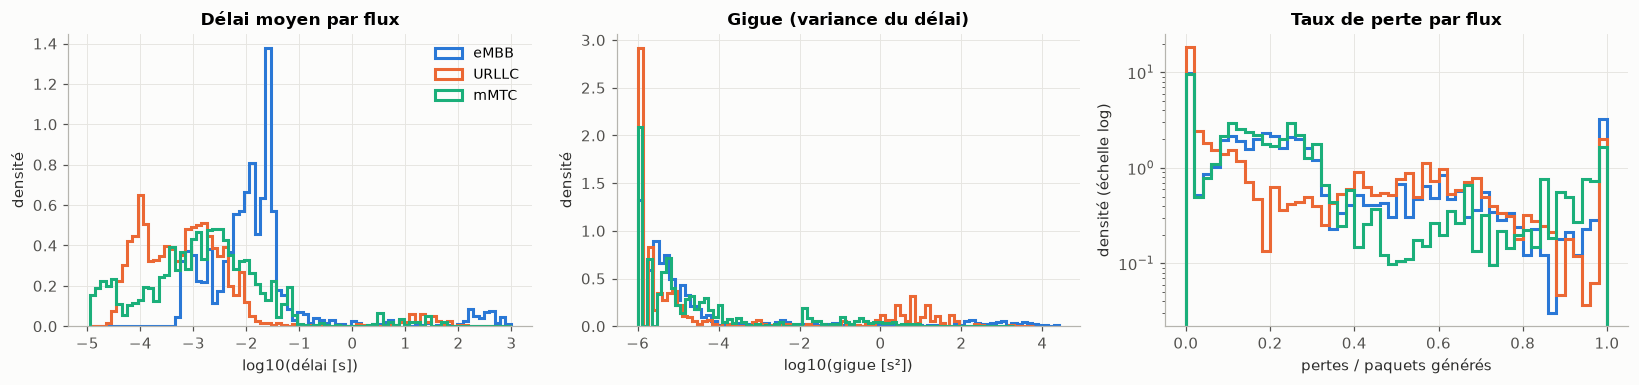

In [ ]:
fig = fig_targets(f); savefig(fig, "L1_03_distributions_cibles"); plt.show()

## 4. Délai en fonction des entrées

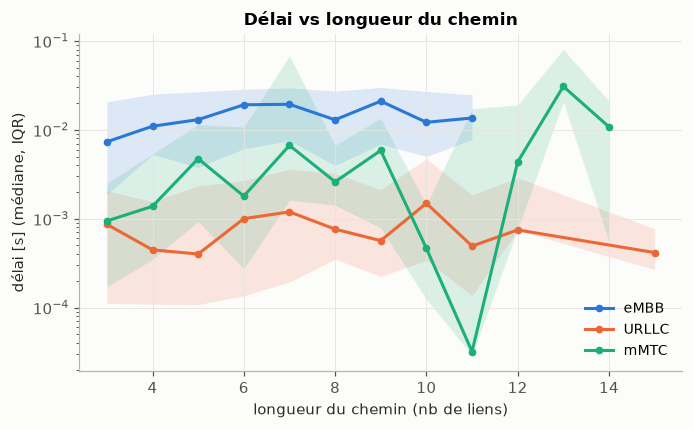

In [ ]:
fig = fig_delay_vs(f, "path_len", np.arange(0.5, 16.5, 1), "longueur du chemin (nb de liens)",
                   "Délai vs longueur du chemin"); savefig(fig, "L1_04_delai_vs_longueur"); plt.show()

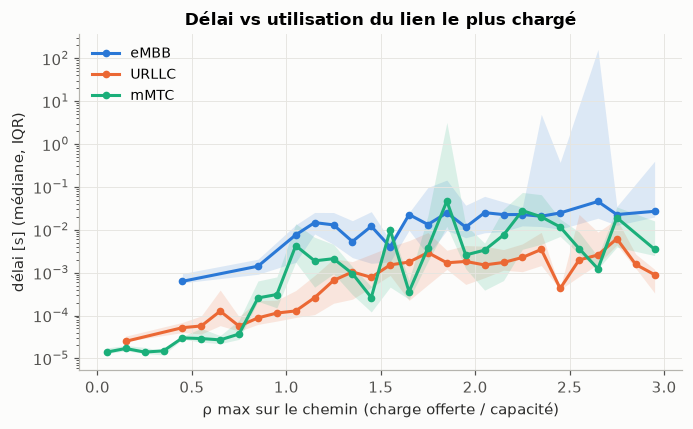

In [ ]:
fig = fig_delay_vs(f, "rho_link_max", np.linspace(0, 3, 31), "ρ max sur le chemin (charge offerte / capacité)",
                   "Délai vs utilisation du lien le plus chargé"); savefig(fig, "L1_05_delai_vs_rho"); plt.show()

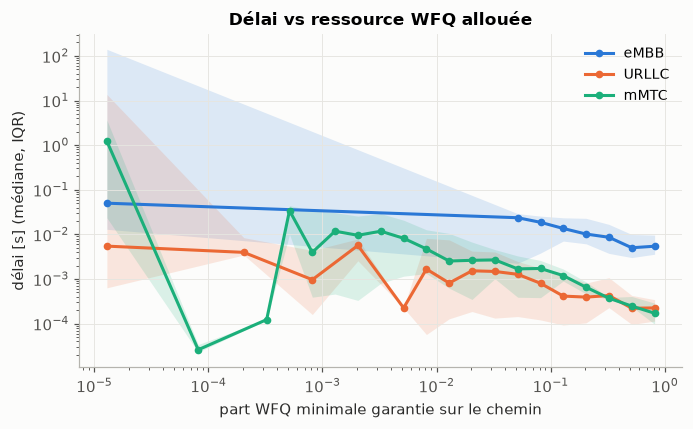

In [ ]:
fig = fig_delay_vs(f, "wfq_share_min", np.logspace(-5, 0, 26), "part WFQ minimale garantie sur le chemin",
                   "Délai vs ressource WFQ allouée", logx=True); savefig(fig, "L1_06_delai_vs_wfq"); plt.show()

**Flux « affamés ».** Les délais supérieurs à la seconde correspondent à des flux dont la file WFQ, sur au moins
un port, a un poids quasi nul (la slice n'a pas de réservation sur ce port car le routage simulé s'écarte du chemin
prévu par l'admission). Vérification :

In [ ]:
starv = pd.crosstab(f.wfq_share_min < 1e-3, pd.cut(f.delay, [-2, 0, 0.01, 0.1, 1, 1e3],
                                                   labels=["aucun paquet", "<10 ms", "10-100 ms", "0,1-1 s", ">1 s"]))
starv.index = ["part min ≥ 1e-3", "part min < 1e-3"]
summary["starvation_crosstab"] = starv.to_dict()
starv

delay,aucun paquet,<10 ms,10-100 ms,"0,1-1 s",>1 s
part min ≥ 1e-3,0,52001,7806,55,16
part min < 1e-3,1,8268,2705,376,2275


## 5. Corrélations

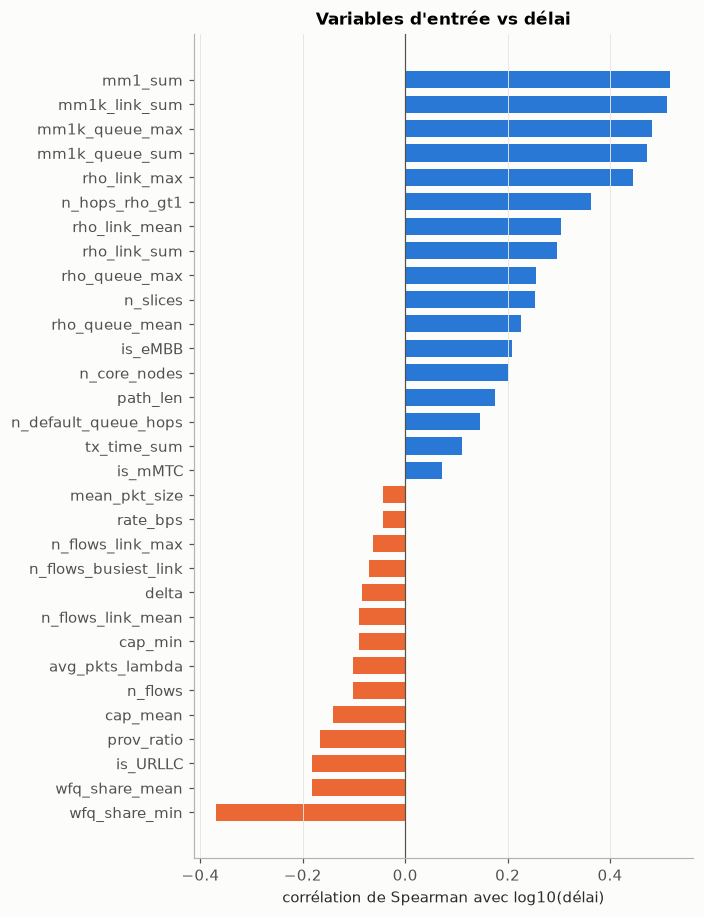

In [ ]:
fig, corr = fig_correlations(f, ALL_FEATURES); savefig(fig, "L1_07_correlations_cible"); plt.show()
summary["spearman_with_log_delay"] = corr.round(3).to_dict()

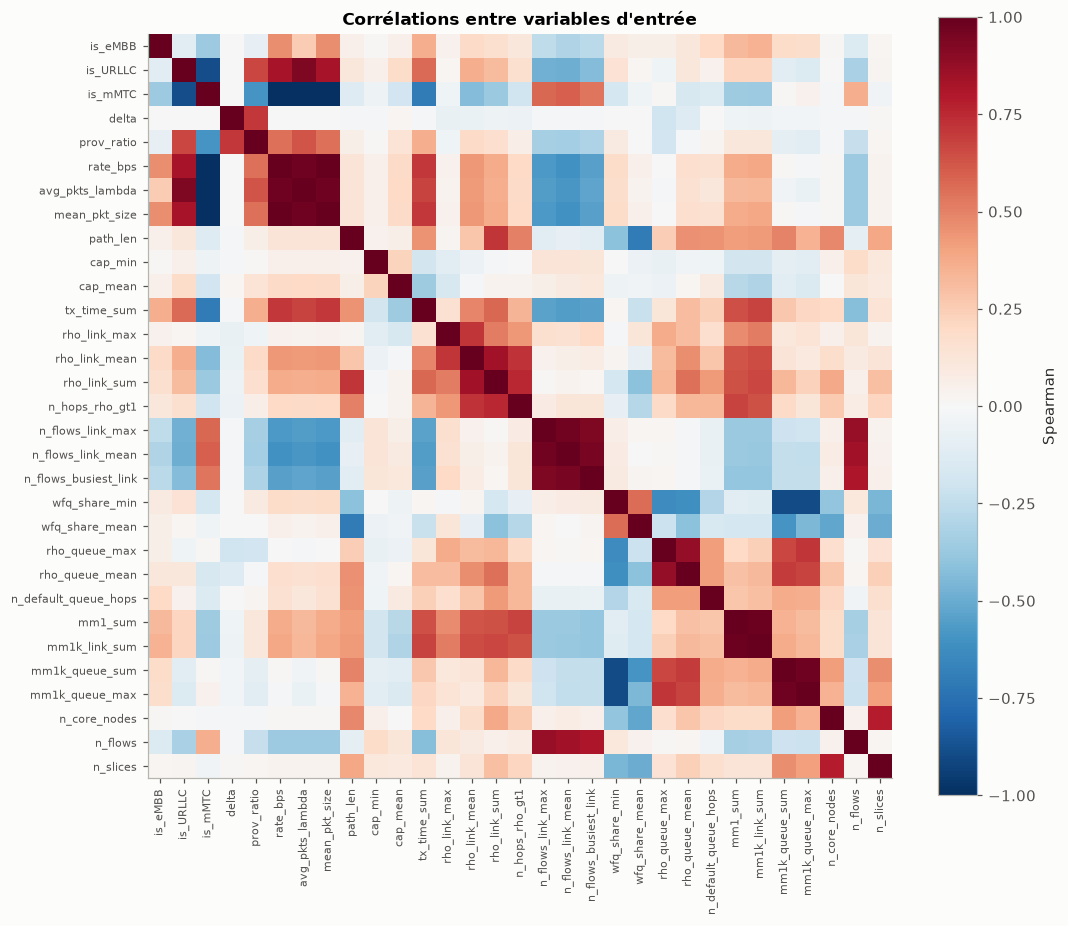

In [ ]:
fig = fig_corr_matrix(f.sample(min(len(f), 200_000), random_state=0), ALL_FEATURES)
savefig(fig, "L1_08_correlations_entrees"); plt.show()

## 6. Dictionnaire des variables (livrable L1)

In [ ]:
vt = save_variables_table()
vt

,variable,table,signification,type,rôle potentiel,justification
0,scenario_id,flows,Numéro du scénario (graph_K / routing_K / slic...,entier,identifiant,Unité de découpage train/val/test (split group...
1,flow_id,flows,Index du flux dans son scénario,entier,identifiant,"Clé technique, aucune signification physique."
2,topology,scenarios,Nom de la topologie Topology Zoo (162 distinctes),catégoriel,identifiant,Sert au split « topologie inédite » ; l'utilis...
3,"src, dst, antenna",flows,"Nœuds origine, destination et antenne du flux",entier,identifiant,Les numéros de nœuds n'ont pas de sens d'un gr...
4,tar_file,scenarios,Archive d'origine,texte,identifiant,Traçabilité uniquement.
5,slice_type,flows,"Type de slice : eMBB, URLLC ou mMTC",catégoriel (3),entrée,"Détermine taille de paquets, débit et file WFQ..."
6,slice_num,flows,Numéro de slice dans le scénario,entier,identifiant,"Identifiant local, pas d'ordre physique."
7,delta,flows,Facteur de provisionnement de la slice (module...,"réel [0,1]",entrée,"C'est la décision d'allocation : δ<0,5 = sous-..."
8,prov_ratio,flows (dérivée),"Réservation / débit réel offert = (0,85+0,3δ)·...",réel,entrée,Mesure directe du sur/sous-provisionnement par...
9,nominal_bw,flows,Débit déclaré dans le fichier slices (bits/s),réel,à exclure,Sous-estime le débit réel de 25 % pour eMBB/mM...


In [ ]:
with open(RESULTS_DIR / "eda_summary.json", "w", encoding="utf-8") as fh:
    json.dump(summary, fh, indent=1, ensure_ascii=False, default=str)
print("écrit :", RESULTS_DIR / "eda_summary.json")

écrit : C:\Users\bourh\Desktop\AI-Based Dynamic Resource Allocation for B5G Network Slicing\results\eda_summary.json
